# DM2026 Lab 2 - Environment test

Run this notebook after `uv sync --locked --python 3.11` from the root of the Lab 2 setup or exercise repository.

1. Create `config/.env` from `config/.env.example` and add at least one API key (Groq or Gemini).
2. Start JupyterLab with `uv run --locked jupyter lab` and use this repository's Python 3.11 environment.
3. Run the cells in order. The SemEval check is skipped in the setup repository and should pass in the exercise repository.


In [10]:
import sys

version = sys.version_info
print(f"Python {version.major}.{version.minor}.{version.micro}")
if version.major != 3 or version.minor != 11:
    print(
        "WARNING: This course targets Python 3.11.x. "
        "Use Python 3.11.x in this project's virtual environment (see README)."
    )
else:
    print("OK: Python 3.11.x")

Python 3.11.16
OK: Python 3.11.x


In [11]:
# Core Lab 2 stack and agent dependencies; this does not download models.
import pandas as pd
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import gensim
import umap
import torch
import transformers
import sentence_transformers
import accelerate
import ipywidgets as widgets
from dotenv import load_dotenv
import cryptography
import langchain_core
import langchain_groq
import langchain_google_genai
import langgraph
import google.genai
import pydantic

print("OK: Lab 2 pipeline, embeddings, agent, and widget imports")


OK: Lab 2 pipeline, embeddings, agent, and widget imports


In [12]:
import importlib.metadata as _metadata

_EXPECTED_WIDGET_VERSIONS = {
    "ipywidgets": "7.8.1",
    "jupyterlab_widgets": "1.1.11",
    "widgetsnbextension": "3.6.10",
}

print("Widget package versions:")
_widget_mismatch = False
for _pkg, _expected in _EXPECTED_WIDGET_VERSIONS.items():
    try:
        _installed = _metadata.version(_pkg)
    except _metadata.PackageNotFoundError:
        _installed = None
    _ok = _installed == _expected
    _widget_mismatch = _widget_mismatch or not _ok
    print(f"  {_pkg}: installed={_installed!r} expected={_expected!r} -> {'OK' if _ok else 'MISMATCH'}")

if _widget_mismatch:
    print(
        "WARNING: at least one widget package version does not match what this lab "
        "pins. This will not show up as an import error anywhere, but it has already "
        "caused the real agentic chat widget to render broken on a real machine. "
        "Re-run `uv sync --locked --python 3.11` in this exact "
        "environment/kernel before continuing, then restart the kernel."
    )
else:
    print("OK: widget package versions match what this course pins.")


Widget package versions:
  ipywidgets: installed='7.8.1' expected='7.8.1' -> OK
  jupyterlab_widgets: installed='1.1.11' expected='1.1.11' -> OK
  widgetsnbextension: installed='3.6.10' expected='3.6.10' -> OK
OK: widget package versions match what this course pins.


In [13]:
from pathlib import Path

root = Path.cwd()
train_files = sorted((root / "data/semeval/train").glob("*-ratings-0to1.train.txt"))
dev_files = sorted((root / "data/semeval/dev").glob("*-ratings-0to1.dev.gold.txt"))
if not (root / "data/semeval").exists():
    print("SKIP: SemEval data is in the exercise repository, not this setup repository.")
else:
    assert len(train_files) == 4 and len(dev_files) == 4, (
        f"Expected four train and four dev files; found {len(train_files)} and {len(dev_files)}."
    )
    sample = pd.read_csv(train_files[0], sep="\t", header=None)
    assert not sample.empty
    print(f"OK: SemEval files (4 train, 4 dev); sample {train_files[0].name}: {len(sample)} rows")


SKIP: SemEval data is in the exercise repository, not this setup repository.


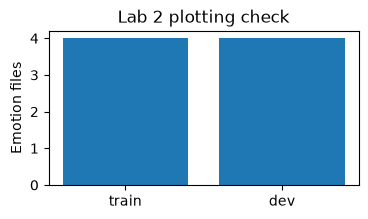

OK: matplotlib plot displayed


In [14]:
# A small plotting check for the libraries used by Lab 2.
fig, ax = plt.subplots(figsize=(4, 2))
ax.bar(["train", "dev"], [4, 4])
ax.set_ylabel("Emotion files")
ax.set_title("Lab 2 plotting check")
plt.show()
print("OK: matplotlib plot displayed")


In [15]:
import os
from pathlib import Path

ENV_PATH = Path("config/.env")


def _is_placeholder(value: str) -> bool:
    v = value.strip().strip('"').strip("'")
    return v.lower().startswith("your-") and v.lower().endswith("-api-key")


def _keys_for(prefix: str) -> list[str]:
    numbered = []
    for i in range(1, 11):
        val = os.getenv(f"{prefix}_{i}")
        if val and not _is_placeholder(val):
            numbered.append(val)
    if numbered:
        return numbered
    single = os.getenv(prefix)
    if single and not _is_placeholder(single):
        return [single]
    return []


if ENV_PATH.is_file():
    load_dotenv(dotenv_path=ENV_PATH)
    print(f"Loaded {ENV_PATH}")
else:
    print(f"WARNING: {ENV_PATH} not found. Copy config/.env.example to config/.env and add keys.")

groq_keys = _keys_for("GROQ_API_KEY")
google_keys = _keys_for("GOOGLE_API_KEY")
print(f"Groq configured: {bool(groq_keys)} ({len(groq_keys)} key(s), values hidden)")
print(f"Gemini configured: {bool(google_keys)} ({len(google_keys)} key(s), values hidden)")
if not groq_keys and not google_keys:
    print("ERROR: Set at least GROQ_API_KEY or GOOGLE_API_KEY in config/.env for API tests below.")

Loaded config\.env
Groq configured: True (1 key(s), values hidden)
Gemini configured: True (1 key(s), values hidden)


In [16]:
if groq_keys:
    from langchain_groq import ChatGroq

    llm = ChatGroq(
        model="openai/gpt-oss-120b",
        groq_api_key=groq_keys[0],
        temperature=0,
        request_timeout=60,
        max_retries=1,
    )
    reply = llm.invoke("Reply with exactly: OK").content
    print(f"Groq API OK — model replied: {reply[:80]!r}")
else:
    print("Skipped Groq test (no GROQ_API_KEY in config/.env).")

Groq API OK — model replied: 'OK'


In [17]:
if google_keys:
    from langchain_google_genai import ChatGoogleGenerativeAI

    llm = ChatGoogleGenerativeAI(
        model="gemini-3.6-flash",
        google_api_key=google_keys[0],
        temperature=0,
        timeout=60,
        max_retries=1,
    )
    reply = llm.invoke("Reply with exactly: OK").content
    print(f"Gemini API OK - model replied: {reply[:80]!r}")
else:
    print("Skipped Gemini test (no GOOGLE_API_KEY in config/.env).")

D:\lu\DataMining\Lab\Lab2\DM2026Labs\DM2026-Lab2-Announcement\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


Gemini API OK - model replied: [{'type': 'text', 'text': 'OK', 'extras': {'signature': 'Ev4CCvsCAWkUfRNiQvtN7RqpybmK16UyP/xjPXsZ1solMdvd5XXRZOrlko05mSVC/0HEEJTrzgBgGVT0dcAFoVlb3PjpQRXuDRPXfC66gNUr7BbQF39i46GqMyl9kirX2VpUbmXfGwjcKsRe5oUB7kgTqA5SthJe5CYC1kDZFZtp2GbtG87paR+H3hhs73bNHuxMDqtD8jG2a2DIMFvm+5IqXPQ2BIHx4lNCXs+uwHZvrcnmKCu01brS5sKDgexiYlVJ2SjXOvCCko298f1ekD5d7XeJ1iwfyhRk2GeZpzRyEPeT0wpN/4sbYFiqslGTQljSMu2zJeF7aV+RubwyYe9cWLSQo5bmoppZZrXdmYWMtmWykKFS7AsMOvkJa3cxTwO87Q4FexY1Y1a7VNs+JGZMotXt/UuCxjQpEmFB8O15jPDNZbl3V6o2JnkyZo5WF1Q+Ak3AcUlkeP+sbhdGOKhWTkoZMO/TIalyxTVMhn9J3WQENvC1v5Vx6moxa1UMDA=='}}]


In [18]:
from IPython.display import display

_test_output = widgets.Output(
    layout=widgets.Layout(border="1px solid #ccc", height="150px", overflow_y="auto", flex="0 0 auto", width="100%")
)
_test_input_row = widgets.HBox(
    [
        widgets.Text(placeholder="(layout test only, not a real chat)", layout={"width": "80%"}),
        widgets.Button(description="Send", button_style="primary"),
    ],
    layout=widgets.Layout(flex="0 0 auto", width="100%", align_items="center"),
)
display(widgets.VBox([_test_output, _test_input_row], layout=widgets.Layout(width="100%")))
with _test_output:
    for _i in range(30):
        print(f"sample chat line {_i}")

print(
    "Check the box above: it should be a small, BORDERED, SCROLLING box holding the "
    "'sample chat line' text, with the text field and blue Send button sitting in "
    "their OWN row directly BELOW it -- not overlapping or mixed in with the text. "
    "If the Send row is missing, floating in the wrong place, or overlapping the "
    "text, that's the same bug the real agentic chat has hit before on our lab's test -- see the "
    "widget-version check above, re-run uv sync / pip install, and restart the "
    "kernel and the notebook server (not just the kernel) before re-running this."
)


Check the box above: it should be a small, BORDERED, SCROLLING box holding the 'sample chat line' text, with the text field and blue Send button sitting in their OWN row directly BELOW it -- not overlapping or mixed in with the text. If the Send row is missing, floating in the wrong place, or overlapping the text, that's the same bug the real agentic chat has hit before on our lab's test -- see the widget-version check above, re-run uv sync / pip install, and restart the kernel and the notebook server (not just the kernel) before re-running this.


## Checklist

- [ ] Python 3.11.x and Lab 2 imports pass
- [ ] Widget package versions say OK
- [ ] SemEval files are found when running in the exercise repository (SKIP is expected in this setup repository)
- [ ] At least one configured LLM API test passes
- [ ] The bordered, scrolling widget renders with the text field and Send button below it

Then continue with `DM2026-Lab2-Master.ipynb` in the exercise repository.
